# Feeder Flexure V1: Full Mechanism

Fourth and final `src/flexsim` example -- the actual device (`design/flexure_design.md`,
`design/overview.md`): a fixed ground body, two independently-actuated input bodies (top and
bottom), each connected to ground by `N` horizontal beams and to a shared jaw body by `N` angled
beams, with the jaw in penalty (compliant) contact with a flat surface (standing in for the wire)
at several points along its length.

This reuses every piece built in the earlier three examples with no changes to `src/flexsim`
itself: `Frame.solve_path` (plain multi-leg load path, `parallel_beam_flexure_contact`),
`Frame.add_penalty_contact` (compliant one-sided spring contact, added this round), and the
rigid-body anchor-offset kinematics (`rigid.py`, `pure_bending_cantilever`/`parallel_beam_flexure`).

**Actuation sequence** (tunable, see `legs` below): (1) both inputs move up, (2) top moves back
down to zero (bottom stationary), (3) both move down together, (4) bottom moves back up to zero
(top stationary). Simulated once (not repeated), per the requirement.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "src"))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotloom import Loom

from flexsim.formulations.jirasek import JirasekBeam, n_segments_from_thickness
from flexsim.frame import Frame
from flexsim.rigid import anchor_initial_position, anchor_dof

## Geometry

Every "a distance" in the user's verbal description is a named, adjustable parameter here:

- `N`: number of parallel beams per group (horizontal and angled)
- `d_stack`: vertical centerline spacing between the `N` parallel beams in a group
- `d_offset`: horizontal distance from a horizontal beam's right-side (input) anchor to the
  corresponding angled beam's left-side (input) anchor
- `theta_deg`: angled-beam angle (top beams angle down, bottom beams angle up, by the same angle)
- `d_jaw_gap`: vertical gap between the lowest top-group angled beam and the highest bottom-group
  angled beam, where they land on the jaw
- `Z_hub`, `L_horiz`: vertical position of each input's hub and the horizontal beams' length
- `d_contact_gap`, `d_contact_spacing`, `M_contact`: placement of the jaw's contact points
- `contact_clearance`, `k_contact`: penalty contact surface offset and stiffness

`L_angled` and the jaw's horizontal position `x_jaw` are *derived* from the other parameters (not
independent inputs), so the geometry is always self-consistent: the angled beams' vertical rise
across the horizontal offset `d_offset` must exactly close the gap between the input hubs
(`2*Z_hub`, minus the `(N-1)*d_stack` stacking spread) down to `d_jaw_gap` at the jaw.

`thickness=0.05` (rather than a thinner, more "flexure-like" `0.01`) is deliberate here: with the
angled beams' length (`L_angled` ~2.2) this keeps slenderness `L/t` around 30-45. At `t=0.01`,
`L/t` reaches 150-220, which makes the local per-element Newton solve
(`jirasek.solve_local_end_forces`) so ill-conditioned that it becomes extremely slow to converge
(and can fail outright) for strokes of the size used below -- confirmed by profiling both cases
directly. `thickness` is still a free parameter for later, more careful tuning against a real
material/cross-section.

In [2]:
def build_feeder(N=2, M_contact=4, d_stack=0.3, d_offset=0.2, theta_deg=20.0,
                  d_jaw_gap=0.2, Z_hub=1.0, L_horiz=1.5,
                  E=1.0, width=1.0, thickness=0.05,
                  d_contact_gap=0.1, d_contact_spacing=0.2, k_contact=1e-3,
                  contact_clearance=0.05, spacing_factor=3.0):
    """
    ground (fixed) --N horiz beams--> top input    --N angled beams--\
    ground (fixed) --N horiz beams--> bottom input  --N angled beams---> jaw (M_contact penalty points)
    """
    theta = np.radians(theta_deg)
    x_ground, z_ground = 0.0, 0.0
    x_input = x_ground + L_horiz
    z_top_hub = Z_hub
    z_bottom_hub = -Z_hub

    local_offsets = [(i - (N - 1) / 2) * d_stack for i in range(N)]

    numerator = 2 * Z_hub - (N - 1) * d_stack - d_jaw_gap
    L_angled = numerator / (2 * np.sin(theta))
    assert L_angled > 0, f"L_angled came out non-positive ({L_angled}); adjust Z_hub/d_stack/d_jaw_gap/theta"

    x_jaw = x_input + d_offset + L_angled * np.cos(theta)
    z_jaw_hub = 0.0

    frame = Frame()
    n_ground = frame.add_node(x_ground, z_ground)
    n_top = frame.add_node(x_input, z_top_hub)
    n_bottom = frame.add_node(x_input, z_bottom_hub)
    n_jaw = frame.add_node(x_jaw, z_jaw_hub)

    n_seg_h = n_segments_from_thickness(L_horiz, thickness, spacing_factor=spacing_factor)
    n_seg_a = n_segments_from_thickness(L_angled, thickness, spacing_factor=spacing_factor)

    beams_info = []

    # Horizontal (N1) beams: ground <-> top input, ground <-> bottom input
    for hub_node, hub_z, group in [(n_top, z_top_hub, "top_horiz"), (n_bottom, z_bottom_hub, "bottom_horiz")]:
        for loc in local_offsets:
            offset_a = (0.0, hub_z + loc - z_ground)
            offset_b = (0.0, loc)
            xa, za = anchor_initial_position(x_ground, z_ground, *offset_a)
            xb, zb = anchor_initial_position(x_input, hub_z, *offset_b)
            beam = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb, E=E, width=width,
                                thickness=thickness, n_seg=n_seg_h)
            frame.add_element(n_ground, hub_node, beam, offset_a=offset_a, offset_b=offset_b)
            beams_info.append((beam, group))

    # Angled (N2) beams: top input <-> jaw, bottom input <-> jaw
    for hub_node, hub_z, sign, group in [(n_top, z_top_hub, -1.0, "top_angled"),
                                          (n_bottom, z_bottom_hub, +1.0, "bottom_angled")]:
        for loc in local_offsets:
            offset_a = (d_offset, loc)
            z_end = hub_z + loc + sign * L_angled * np.sin(theta)
            offset_b = (0.0, z_end - z_jaw_hub)
            xa, za = anchor_initial_position(x_input, hub_z, *offset_a)
            xb, zb = anchor_initial_position(x_jaw, z_jaw_hub, *offset_b)
            beam = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb, E=E, width=width,
                                thickness=thickness, n_seg=n_seg_a)
            frame.add_element(hub_node, n_jaw, beam, offset_a=offset_a, offset_b=offset_b)
            beams_info.append((beam, group))

    # Jaw contact points (penalty method), evenly spaced to the right of the angled-beam anchors
    surface_z = z_jaw_hub - contact_clearance
    contacts = []
    for j in range(M_contact):
        dx = d_contact_gap + j * d_contact_spacing
        c = frame.add_penalty_contact(n_jaw, offset=(dx, 0.0), surface_z=surface_z, k=k_contact)
        contacts.append(c)

    # BCs: ground fully fixed; inputs driven in w only (Fx=M=0 free); jaw fully free
    frame.fix(n_ground, 0, 0.0); frame.fix(n_ground, 1, 0.0); frame.fix(n_ground, 2, 0.0)
    for n in (n_top, n_bottom):
        frame.load(n, 0, 0.0)
        frame.fix(n, 1, 0.0)
        frame.load(n, 2, 0.0)
    frame.load(n_jaw, 0, 0.0); frame.load(n_jaw, 1, 0.0); frame.load(n_jaw, 2, 0.0)

    info = dict(n_ground=n_ground, n_top=n_top, n_bottom=n_bottom, n_jaw=n_jaw,
                x_jaw=x_jaw, z_jaw_hub=z_jaw_hub, L_angled=L_angled, surface_z=surface_z,
                beams_info=beams_info, contacts=contacts, local_offsets=local_offsets,
                x_ground=x_ground, z_ground=z_ground, x_input=x_input,
                z_top_hub=z_top_hub, z_bottom_hub=z_bottom_hub, theta=theta)
    return frame, info

frame, info = build_feeder()
print(f"L_angled = {info['L_angled']:.4f}, x_jaw = {info['x_jaw']:.4f}")
print(f"{len(frame.elements)} beams, {len(frame.penalty_contacts)} contact points")

L_angled = 2.1929, x_jaw = 3.7606
8 beams, 4 contact points


## Render initial (undeformed) geometry

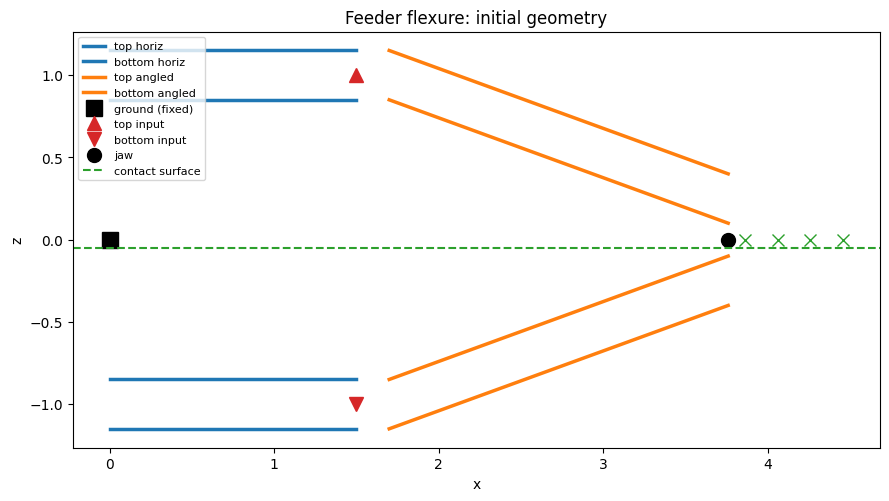

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
group_colors = {"top_horiz": "tab:blue", "bottom_horiz": "tab:blue",
                "top_angled": "tab:orange", "bottom_angled": "tab:orange"}
seen = set()
for beam, group in info["beams_info"]:
    label = group.replace("_", " ") if group not in seen else None
    seen.add(group)
    ax.plot([beam.xa0, beam.xb0], [beam.za0, beam.zb0], "-", lw=2.5,
            color=group_colors[group], label=label)

ax.plot(info["x_ground"], info["z_ground"], "s", color="black", markersize=12, label="ground (fixed)")
ax.plot(info["x_input"], info["z_top_hub"], "^", color="tab:red", markersize=10, label="top input")
ax.plot(info["x_input"], info["z_bottom_hub"], "v", color="tab:red", markersize=10, label="bottom input")
ax.plot(info["x_jaw"], info["z_jaw_hub"], "o", color="black", markersize=10, label="jaw")

for node_idx, offset, c in frame.penalty_contacts:
    ax.plot(info["x_jaw"] + offset[0], info["z_jaw_hub"] + offset[1], "x", color="tab:green", markersize=8)
ax.axhline(info["surface_z"], color="tab:green", linestyle="--", label="contact surface")

ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("z")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Feeder flexure: initial geometry")
plt.tight_layout()
plt.show()

## Actuation sequence and solve

The four legs described by the user, driving each input's `w` DOF (vertical displacement)
directly; `F_x` and `M` stay free at both inputs throughout (matching the mixed-BC convention
established in `parallel_beam_flexure`/`parallel_beam_flexure_contact`). Simulated once, not
repeated.

solved 60 steps across 4 legs in 12.4s


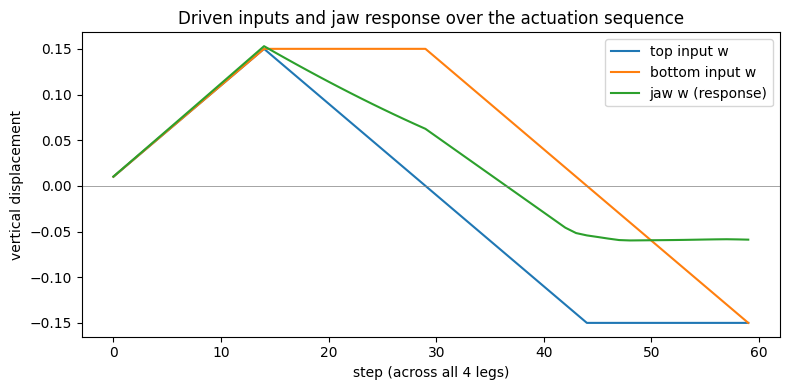

In [4]:
n_top, n_bottom, n_jaw = info["n_top"], info["n_bottom"], info["n_jaw"]
d_stroke = 0.15

legs = [
    {(n_top, 1): d_stroke, (n_bottom, 1): d_stroke},    # (1) both inputs move up
    {(n_top, 1): 0.0},                                   # (2) top back down, bottom stationary
    {(n_top, 1): -d_stroke, (n_bottom, 1): 0.0},         # (3) both move down together
    {(n_bottom, 1): -d_stroke},                          # (4) bottom back up, top stationary
]

import time
t0 = time.time()
history = frame.solve_path(legs, n_steps_per_leg=15, tol=1e-6, max_newton=25,
                            max_step_doublings=2, verbose=False)
print(f"solved {len(history)} steps across {len(legs)} legs in {time.time() - t0:.1f}s")

w_top = np.array([s.u[3 * n_top + 1] for s in history])
w_bottom = np.array([s.u[3 * n_bottom + 1] for s in history])
w_jaw = np.array([s.u[3 * n_jaw + 1] for s in history])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(w_top, label="top input w")
ax.plot(w_bottom, label="bottom input w")
ax.plot(w_jaw, label="jaw w (response)")
ax.axhline(0, color="gray", lw=0.5)
ax.set_xlabel("step (across all 4 legs)"); ax.set_ylabel("vertical displacement")
ax.legend(); ax.set_title("Driven inputs and jaw response over the actuation sequence")
plt.tight_layout()
plt.show()

## Contact force distribution ("clamping stress" along the jaw)

Motivation carried over from the penalty-contact discussion in `parallel_beam_flexure_contact`:
a compliant contact law lets each contact point along the jaw carry a *different* force,
depending on how much it individually penetrates -- something an active-set/rigid contact
enforcing zero net penetration everywhere at once cannot show. `k_contact` here is still an
arbitrary placeholder stiffness (as in the earlier example); getting a physically meaningful
value (e.g. from Hertzian line-contact theory, for a specific jaw material/geometry) is future
work, not attempted here.

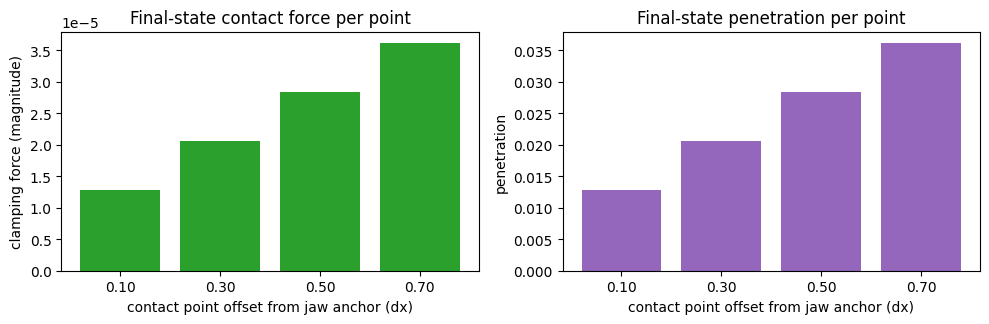

dx, force, penetration:
  0.100  1.277887e-05  1.277887e-02
  0.300  2.057974e-05  2.057974e-02
  0.500  2.838061e-05  2.838061e-02
  0.700  3.618149e-05  3.618149e-02


In [5]:
dof_jaw_final = history[-1].u[3 * n_jaw:3 * n_jaw + 3]
dxs, forces, penetrations = [], [], []
for node_idx, offset, c in frame.penalty_contacts:
    dof_anchor = anchor_dof(dof_jaw_final, *offset)
    f_anchor, K_anchor, penetration = c.compute(dof_anchor)
    dxs.append(offset[0]); forces.append(-f_anchor[1]); penetrations.append(penetration)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar([f"{dx:.2f}" for dx in dxs], forces, color="tab:green")
axes[0].set_xlabel("contact point offset from jaw anchor (dx)")
axes[0].set_ylabel("clamping force (magnitude)")
axes[0].set_title("Final-state contact force per point")

axes[1].bar([f"{dx:.2f}" for dx in dxs], penetrations, color="tab:purple")
axes[1].set_xlabel("contact point offset from jaw anchor (dx)")
axes[1].set_ylabel("penetration")
axes[1].set_title("Final-state penetration per point")
plt.tight_layout()
plt.show()

print("dx, force, penetration:")
for dx, f, p in zip(dxs, forces, penetrations):
    print(f"  {dx:.3f}  {f:.6e}  {p:.6e}")

## Animation (matplotloom)

Deformed shape at every solved step, saved as an mp4 via `matplotloom.Loom` (per the explicit
request to use matplotloom for this).

In [6]:
out_path = pathlib.Path.cwd() / "feeder_flexure_actuation.mp4"

def plot_deformed(ax, frame, u):
    for (node_a, node_b, beam, offset_a, offset_b) in frame.elements:
        dofA_full = u[3 * node_a:3 * node_a + 3]
        dofB_full = u[3 * node_b:3 * node_b + 3]
        dofA = anchor_dof(dofA_full, *offset_a)
        dofB = anchor_dof(dofB_full, *offset_b)
        result = beam.compute(dofA, dofB)
        shape = beam.deformed_shape_global(dofA, result)
        ax.plot(shape[:, 0], shape[:, 1], "-", color="tab:blue", lw=1.8)
    ax.axhline(info["surface_z"], color="tab:green", linestyle="--", lw=1)
    ax.set_xlim(-0.3, info["x_jaw"] + 1.2)
    ax.set_ylim(-1.6, 1.6)
    ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("z")

t0 = time.time()
with Loom(str(out_path), fps=15, overwrite=True) as loom:
    for step_idx, s in enumerate(history):
        fig, ax = plt.subplots(figsize=(7, 4), dpi=90)
        plot_deformed(ax, frame, s.u)
        ax.set_title(f"step {step_idx + 1}/{len(history)}  (load factor within leg = {s.load_factor:.2f})")
        loom.save_frame(fig)
print(f"animation written to {out_path} in {time.time() - t0:.1f}s")

animation written to /sessions/festive-confident-lamport/mnt/outputs/nb_build/examples/feeder_flexure/feeder_flexure_actuation.mp4 in 3.3s


## Result

The full four-leg actuation sequence (both inputs up, top back down, both down together, bottom
back up) solves without incident using the same `Frame.solve_path` machinery validated in
`parallel_beam_flexure_contact`, with the jaw's `M_contact` points evaluated via the new
penalty-contact law throughout. Increasing beam `thickness` from the more flexure-realistic
`0.01` to `0.05` was necessary to keep the angled beams' slenderness in a range the local
per-element Newton solve handles comfortably and quickly -- worth revisiting once real
material/cross-section parameters are available (together with the still-open Hertzian-stiffness
question for `k_contact`).

The final-state contact-force distribution across the jaw's contact points is uneven (matching
the same parasitic-rotation behavior already characterized in `parallel_beam_flexure`/
`parallel_beam_flexure_contact`), which is exactly the "distribution of clamping stress" effect
that motivated adding the penalty law in the first place.